In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

hex_grid = gpd.read_file(
    "../data/processed/sydney_hex_features_v3.geojson"
).to_crs("EPSG:7856")

sa1 = gpd.read_file(
    "../data/processed/sydney_study_sa1_final.geojson"
).to_crs("EPSG:7856")

print("Hexagons:", len(hex_grid))
print("SA1 areas:", len(sa1))
print("SA1 columns:", sa1.columns.tolist())

Hexagons: 16228
SA1 areas: 10503
SA1 columns: ['SA1_CODE21', 'CHG_FLAG21', 'CHG_LBL21', 'SA2_CODE21', 'SA2_NAME21', 'SA3_CODE21', 'SA3_NAME21', 'SA4_CODE21', 'SA4_NAME21', 'GCC_CODE21', 'GCC_NAME21', 'STE_CODE21', 'STE_NAME21', 'AUS_CODE21', 'AUS_NAME21', 'AREASQKM21', 'LOCI_URI21', 'sa1_code', 'population', 'pop_density', 'geometry']


In [4]:
from pathlib import Path

print("Raw SA1 files:")
for path in Path("../data/raw/abs_sa1_2021").rglob("*"):
    if path.is_file():
        print(path)

print("\nProcessed population files:")
for path in Path("../data/processed").glob("*population*"):
    print(path)

Raw SA1 files:
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.xml
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.dbf
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.shp
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.shx
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.prj

Processed population files:
../data/processed/sa1_population_2021.csv


In [5]:
from pathlib import Path

print("Raw SA1 files:")
for path in Path("../data/raw/abs_sa1_2021").rglob("*"):
    if path.is_file():
        print(path)

print("\nProcessed population files:")
for path in Path("../data/processed").glob("*population*"):
    print(path)

Raw SA1 files:
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.xml
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.dbf
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.shp
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.shx
../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.prj

Processed population files:
../data/processed/sa1_population_2021.csv


In [6]:
print("SA1 count:", len(sa1))
print("Total population:", sa1["population"].sum())

display(
    sa1[
        ["SA1_CODE21", "population", "pop_density", "AREASQKM21"]
    ].head()
)

SA1 count: 10503
Total population: 4560390.0


,SA1_CODE21,population,pop_density,AREASQKM21
0,11501129001,768.0,2802.919708,0.2740
1,11501129002,787.0,4515.203672,0.1743
2,11501129003,693.0,4187.311178,0.1655
3,11501129004,579.0,6172.707889,0.0938
4,11501129005,721.0,5262.773723,0.1370


In [7]:
sa1_all = gpd.read_file(
    "../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.shp"
)

print("Original SA1 count:", len(sa1_all))
print("CRS:", sa1_all.crs)

display(sa1_all[["SA1_CODE21", "AREASQKM21"]].head())

Original SA1 count: 61845
CRS: EPSG:7844


,SA1_CODE21,AREASQKM21
0,10102100701,362.8727
1,10102100702,229.7459
2,10102100703,2.3910
3,10102100704,1.2816
4,10102100705,1.1978


In [8]:
population = pd.read_csv(
    "../data/processed/sa1_population_2021.csv"
)

print(population.columns.tolist())
display(population.head())

['sa1_code', 'population']


,sa1_code,population
0,10102100701,305
1,10102100702,301
2,10102100703,471
3,10102100704,522
4,10102100705,423


In [9]:
# Convert both identifiers to strings
sa1_all["sa1_code"] = (
    sa1_all["SA1_CODE21"].astype(str)
)

population["sa1_code"] = (
    population["sa1_code"].astype(str)
)

# Merge Census population
sa1_all = sa1_all.merge(
    population[["sa1_code", "population"]],
    on="sa1_code",
    how="left",
    validate="many_to_one"
)

print("SA1s with population:", sa1_all["population"].notna().sum())
print("SA1s without population:", sa1_all["population"].isna().sum())

SA1s with population: 19750
SA1s without population: 42095


In [10]:
sa1_all = sa1_all.to_crs("EPSG:7856")

# Build the context area around all prediction hexagons
context_area = (
    hex_grid.geometry.union_all()
    .buffer(500)
)

sa1_context = sa1_all[
    sa1_all.geometry.intersects(context_area)
].copy()

print("SA1s in population context:", len(sa1_context))
print(
    "Missing population:",
    sa1_context["population"].isna().sum()
)

SA1s in population context: 10873
Missing population: 0


In [11]:
sa1_context["sa1_area_m2"] = (
    sa1_context.geometry.area
)

print(
    "SA1s with zero area:",
    (sa1_context["sa1_area_m2"] <= 0).sum()
)

print(
    "Total context SA1 population:",
    sa1_context["population"].sum()
)

SA1s with zero area: 0
Total context SA1 population: 4701164.0


In [12]:
# Get hexagon centres
centres = hex_grid[["hex_id", "geometry"]].copy()
centres["geometry"] = centres.geometry.centroid

# Create buffers
buffers_250 = centres.copy()
buffers_250["geometry"] = centres.geometry.buffer(250)

buffers_500 = centres.copy()
buffers_500["geometry"] = centres.geometry.buffer(500)

print("250m buffers:", len(buffers_250))
print("500m buffers:", len(buffers_500))

250m buffers: 16228
500m buffers: 16228


In [13]:
def calculate_buffer_population(buffers, sa1):
    intersections = gpd.overlay(
        buffers[["hex_id", "geometry"]],
        sa1[["population", "sa1_area_m2", "geometry"]],
        how="intersection",
        keep_geom_type=True
    )

    intersections["overlap_area_m2"] = (
        intersections.geometry.area
    )

    intersections["population_contribution"] = (
        intersections["population"]
        * intersections["overlap_area_m2"]
        / intersections["sa1_area_m2"]
    )

    return (
        intersections.groupby("hex_id")[
            "population_contribution"
        ]
        .sum()
    )

In [14]:
pop_250 = calculate_buffer_population(
    buffers_250, sa1_context
)

print("250m population complete")

pop_500 = calculate_buffer_population(
    buffers_500, sa1_context
)

print("500m population complete")

250m population complete
500m population complete


In [15]:
hex_grid["population_250m"] = (
    hex_grid["hex_id"]
    .map(pop_250)
    .fillna(0)
)

hex_grid["population_500m"] = (
    hex_grid["hex_id"]
    .map(pop_500)
    .fillna(0)
)

display(
    hex_grid[
        ["population_est", "population_250m", "population_500m"]
    ].describe()
)

,population_est,population_250m,population_500m
count,16228.000000,16228.000000,16228.000000
mean,276.781712,426.762777,1679.358701
std,321.045201,478.943026,1669.671611
min,0.000000,0.000000,0.000000
25%,20.575746,34.042615,205.301826
50%,214.048265,337.061436,1408.326203
75%,412.617155,631.846198,2474.595695
max,4909.861641,7888.568620,18618.166943


In [16]:
import numpy as np

print("500m >= 250m:",
    (
        hex_grid["population_500m"]
        >= hex_grid["population_250m"] - 1e-6
    ).all()
)

print("250m >= inside hexagon:",
    (
        hex_grid["population_250m"]
        >= hex_grid["population_est"] - 1e-6
    ).all()
)

print("Negative population values:",
    (
        hex_grid[["population_250m", "population_500m"]] < 0
    ).sum().sum()
)

print("Missing population values:",
    hex_grid[["population_250m", "population_500m"]]
    .isna().sum().sum()
)

500m >= 250m: True
250m >= inside hexagon: True
Negative population values: 0
Missing population values: 0


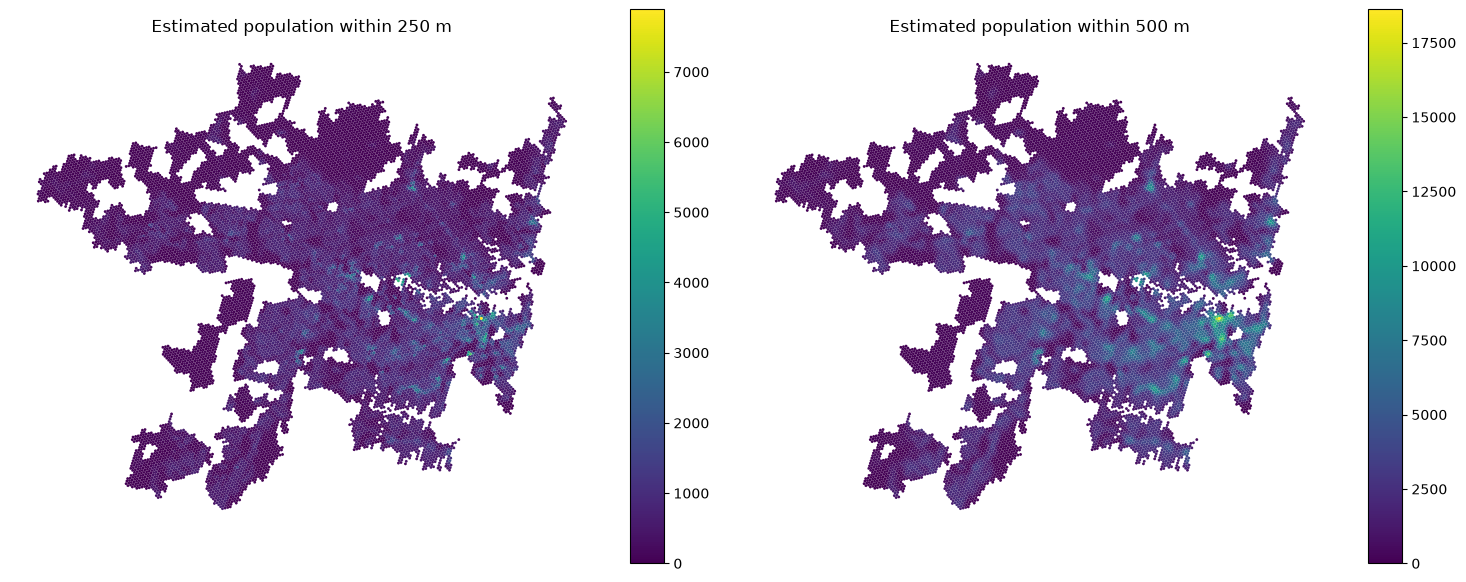

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

hex_grid.plot(
    column="population_250m",
    ax=axes[0],
    cmap="viridis",
    legend=True,
    edgecolor="none"
)

axes[0].set_title("Estimated population within 250 m")
axes[0].set_axis_off()

hex_grid.plot(
    column="population_500m",
    ax=axes[1],
    cmap="viridis",
    legend=True,
    edgecolor="none"
)

axes[1].set_title("Estimated population within 500 m")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

In [18]:
hex_grid.to_file(
    "../data/processed/sydney_hex_features_v4.geojson",
    driver="GeoJSON"
)

hex_grid.drop(columns="geometry").to_csv(
    "../data/processed/sydney_hex_features_v4.csv",
    index=False
)

print("Saved", len(hex_grid), "hexagons")

Saved 16228 hexagons
